
# Naive Bayes

Naive Bayes is a supervised machine learning algorithm based on Bayes' Theorem. It is primarily used for classification tasks.

The algorithm calculates the probability of a data point belonging to different classes and predicts the class with the highest probability.

It is called "naive" because it assumes that features are conditionally independent of one another given the target class.

### How Naive Bayes Works
Naive Bayes applies Bayes' Theorem to estimate the probability that an observation belongs to a particular class based on its features.

The algorithm follows these steps:

1. **Calculate prior probabilities:** Determine the initial probability of each target class.
2. **Calculate likelihoods:** Estimate how likely the observed features are for each class.
3. **Apply Bayes' Theorem:** Combine prior probabilities and likelihoods to calculate posterior probabilities.
4. **Make a prediction:** Assign the observation to the class with the highest posterior probability.

### Key Characteristics
- Based on Bayes' Theorem.
- Uses probability to make predictions.
- Efficient and computationally inexpensive.
- Works well with high-dimensional datasets.
- Commonly used in spam detection, sentiment analysis, and text classification.

### Types of Naive Bayes
1. Gaussian Naive Bayes
2. Multinomial Naive Bayes
3. Bernoulli Naive Bayes
4. Complement Naive Bayes
5. Categorical Naive Bayes

### Objectives
- Understand the Naive Bayes algorithm.
- Implement different Naive Bayes classifiers.
- Evaluate classification performance.
- Compare model performance.
- Explore the effect of hyperparameter tuning.


## Bayes' Theorem

Bayes' Theorem is the mathematical foundation of the Naive Bayes algorithm. It describes how to update the probability of an event or hypothesis when new evidence becomes available.

The theorem calculates the probability of an event occurring given that another event has already occurred.

### Mathematical Formula

$$
P(A \mid B) = \frac{P(B \mid A)P(A)}{P(B)}
$$
### Components of Bayes' Theorem

- **P(A|B) – Posterior Probability:** The probability of event A occurring given that event B has occurred.
- **P(B|A) – Likelihood:** The probability of observing event B given that event A has occurred.
- **P(A) – Prior Probability:** The initial probability of event A before considering new evidence.
- **P(B) – Evidence:** The probability of observing event B.

### Application in Naive Bayes

In machine learning:

- A represents a target class.
- B represents the observed features of a data point.
- The algorithm calculates the posterior probability for each possible class.
- The class with the highest posterior probability is selected as the prediction.

### Example

Consider an email classification problem where the objective is to determine whether an email is spam.

Suppose an email contains the word "Congratulations."

Naive Bayes uses the probability of spam emails containing this word, together with the prior probability of spam, to estimate the probability that the email is spam.

It performs this calculation for each possible class and predicts the class with the highest probability.

**In summary:** Bayes' Theorem allows Naive Bayes to use observed evidence to update class probabilities and make predictions.


In [1]:
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import (GaussianNB,MultinomialNB,BernoulliNB)
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,roc_auc_score,roc_curve)
import warnings

warnings.filterwarnings('ignore')

In [2]:
# Load the dataset
cancer = load_breast_cancer()

# Create DataFrame
cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

# Add target variable
cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [4]:
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


target
1    357
0    212
Name: count, dtype: int64


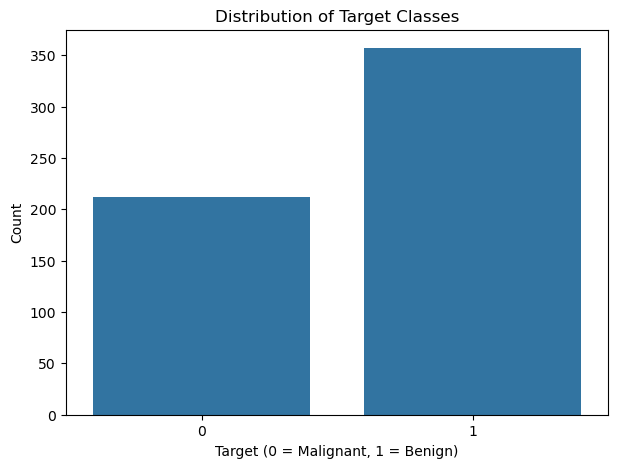

In [5]:
# target distribution
# Count target classes
print(cancer_df['target'].value_counts())

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target')

plt.title('Distribution of Target Classes')
plt.xlabel('Target (0 = Malignant, 1 = Benign)')
plt.ylabel('Count')
plt.show()

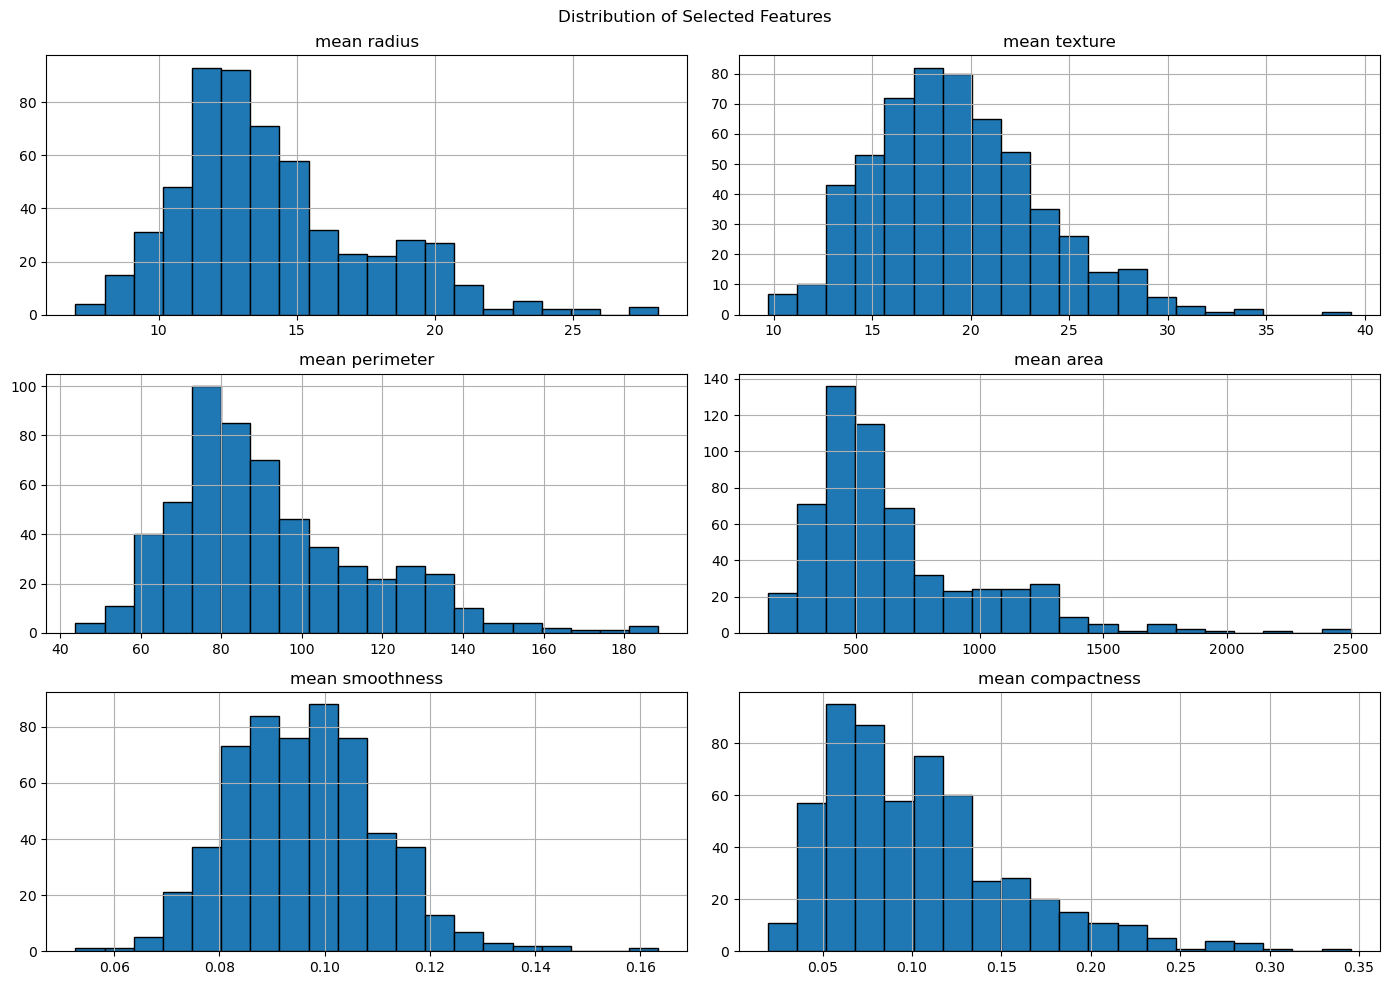

In [6]:
# feature distribution

# Plot distributions of selected features
selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean compactness'
]

cancer_df[selected_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Selected Features')
plt.tight_layout()
plt.show()

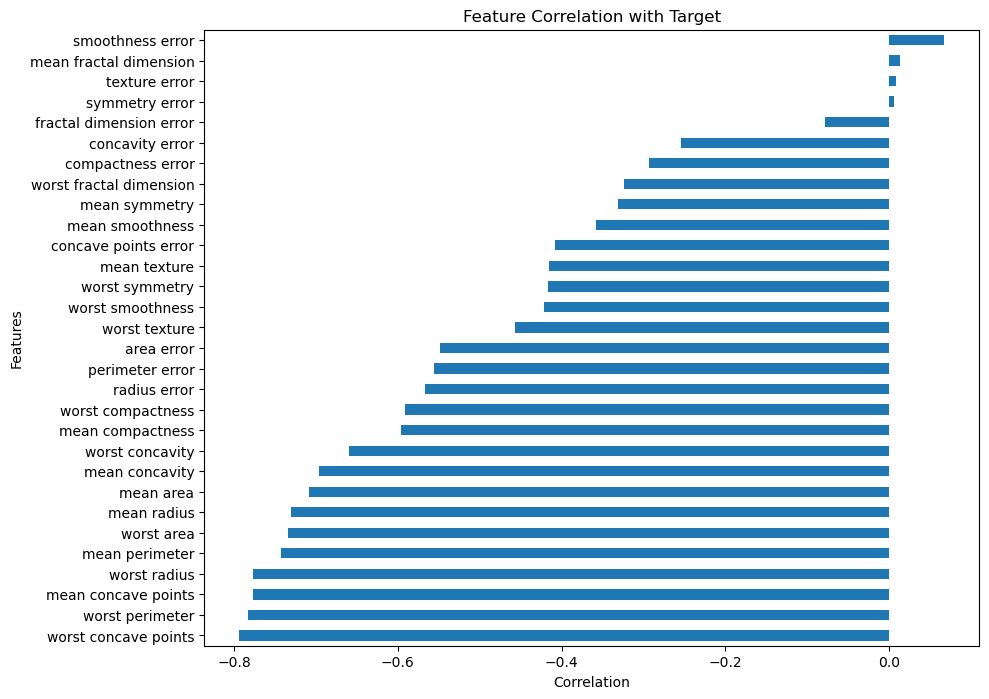

In [7]:
# feature rlship with target

target_correlation = (cancer_df.corr()['target'].drop('target').sort_values())

plt.figure(figsize=(10, 8))

target_correlation.plot(kind='barh')

plt.title('Feature Correlation with Target')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.show()

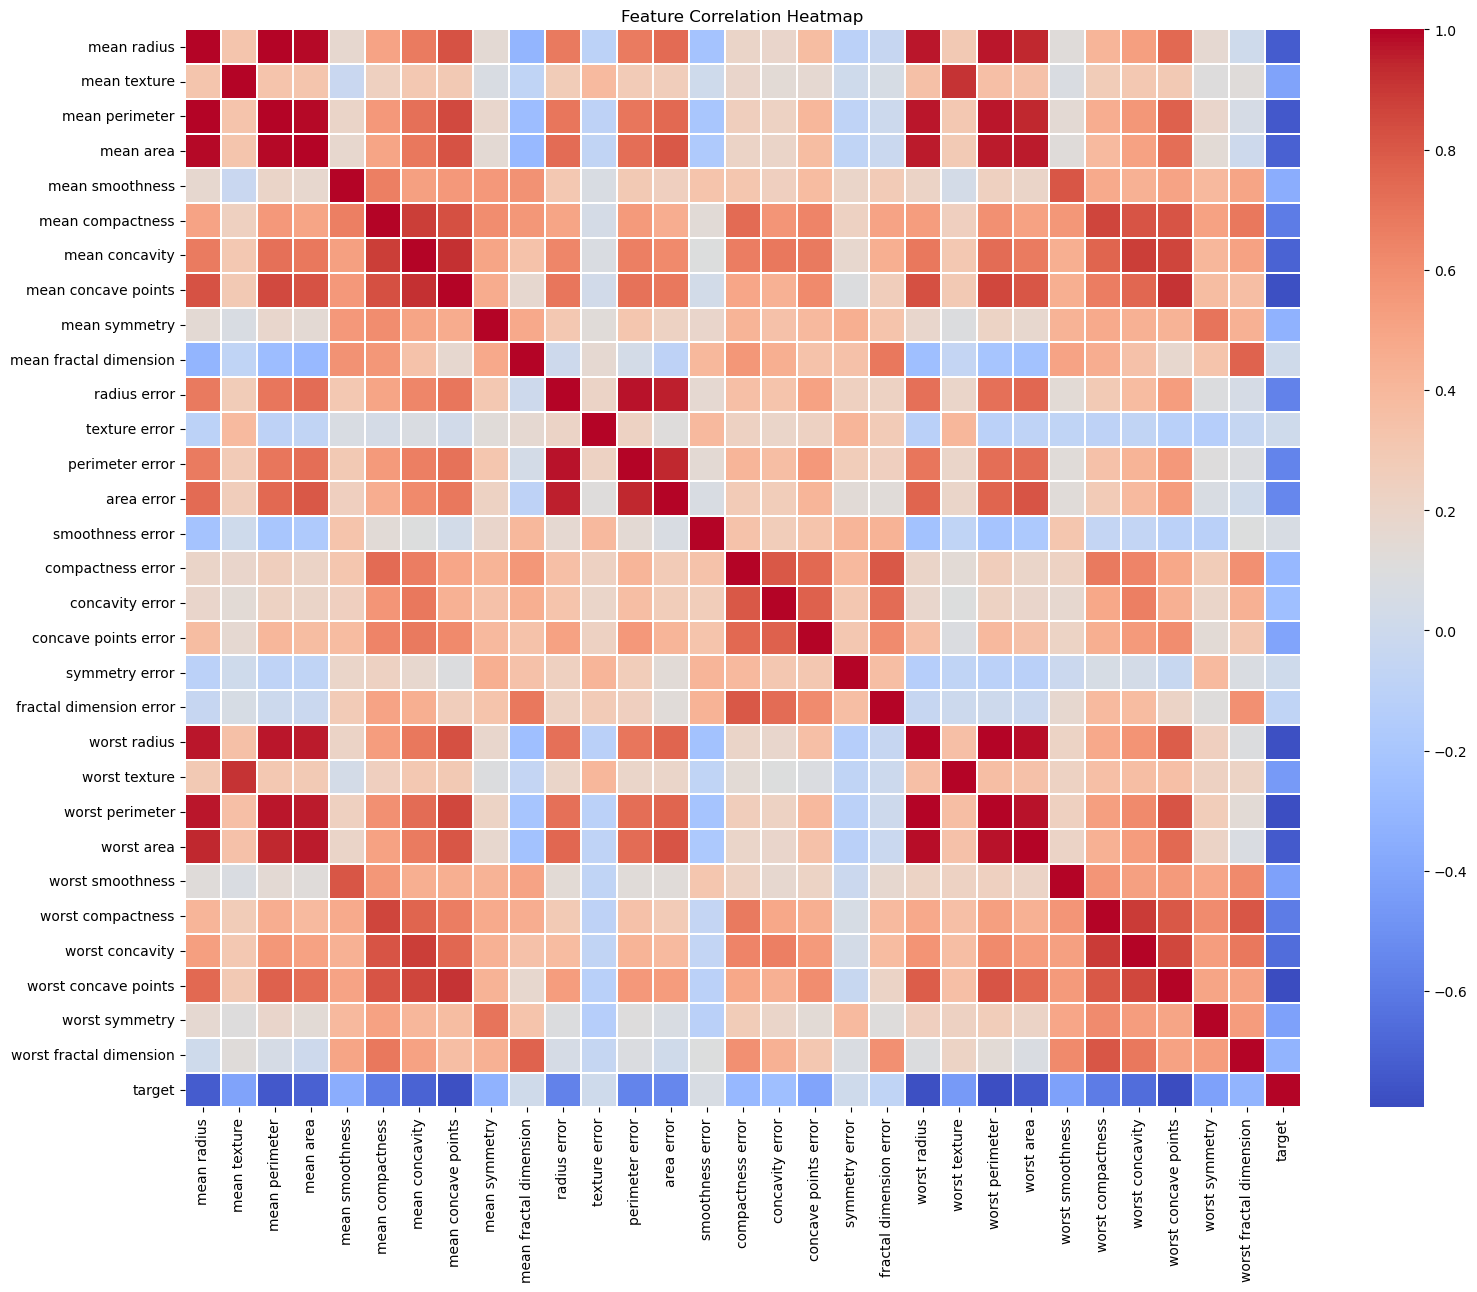

In [8]:
# correlation analysis

plt.figure(figsize=(18, 14))

correlation_matrix = cancer_df.corr()

sns.heatmap(correlation_matrix,cmap='coolwarm',annot=False,linewidths=0.3)

plt.title('Feature Correlation Heatmap')
plt.show()

In [9]:
# Preprocessing
# Separate features and target
X = cancer_df.drop('target', axis=1)
y = cancer_df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [10]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [11]:
# Gaussian model
# Initialize Gaussian Naive Bayes
gnb = GaussianNB()

# Train the model
gnb.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [12]:
# predictions

# Training predictions
y_train_pred = gnb.predict(X_train)

# Testing predictions
y_test_pred = gnb.predict(X_test)

# Predicted probabilities
y_test_proba = gnb.predict_proba(X_test)[:, 1]

In [13]:
# evaluation
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {accuracy:.6f}")
print(f"Precision: {precision:.6f}")
print(f"Recall:    {recall:.6f}")
print(f"F1 Score:  {f1:.6f}")
print(f"ROC-AUC:   {roc_auc:.6f}")

Accuracy:  0.938596
Precision: 0.945205
Recall:    0.958333
F1 Score:  0.951724
ROC-AUC:   0.987765


In [14]:
# classification report
print(classification_report(y_test,y_test_pred,target_names=['Malignant', 'Benign']))


              precision    recall  f1-score   support

   Malignant       0.93      0.90      0.92        42
      Benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [17]:
# training vs testing

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.6f}")
print(f"Testing Accuracy:  {test_accuracy:.6f}")

Training Accuracy: 0.940659
Testing Accuracy:  0.938596


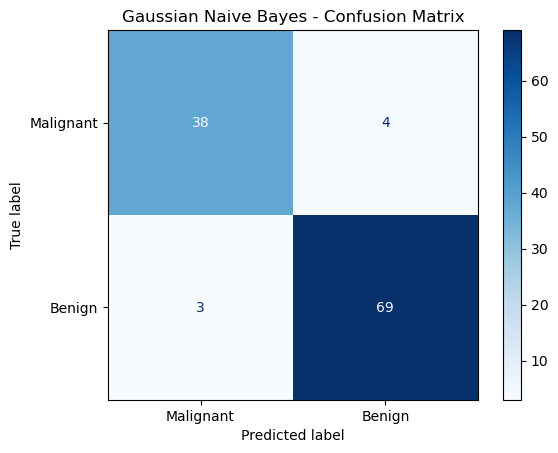

In [15]:
# confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Malignant', 'Benign'])

disp.plot(cmap='Blues')
plt.title('Gaussian Naive Bayes - Confusion Matrix')
plt.show()

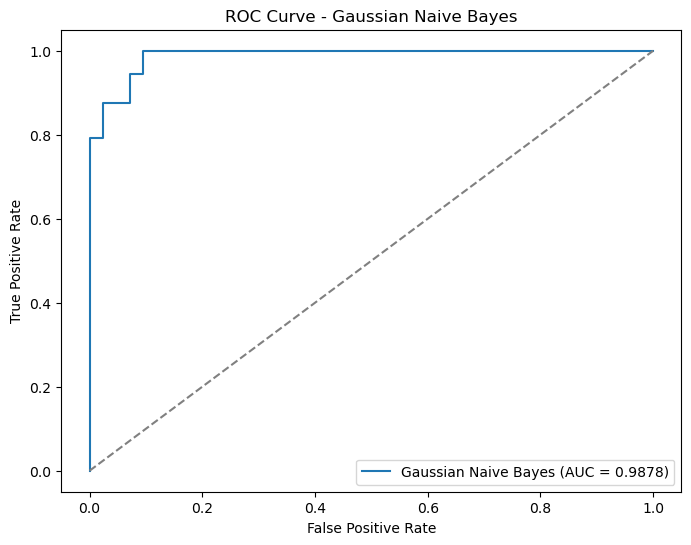

In [16]:
# ROC Curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'Gaussian Naive Bayes (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gaussian Naive Bayes')
plt.legend()
plt.show()

In [18]:

# Display class-specific means
class_means = pd.DataFrame(gnb.theta_,columns=X.columns,index=['Malignant', 'Benign'])

display(class_means.T.head(15))

,Malignant,Benign
mean radius,17.381235,12.090428
mean texture,21.579882,17.856035
mean perimeter,114.830647,77.675123
mean area,966.820000,458.690526
mean smoothness,0.102994,0.092095
mean compactness,0.146145,0.078652
mean concavity,0.162363,0.045548
mean concave points,0.087607,0.024924
mean symmetry,0.193631,0.172856
mean fractal dimension,0.062829,0.062814


In [19]:
# Hyperparameter Tuning

param_grid = {
    'var_smoothing': np.logspace(-12, -6, 7)
}
# Gridsearch
gnb_grid = GridSearchCV(estimator=GaussianNB(),param_grid=param_grid,cv=5,scoring='f1',n_jobs=-1,verbose=1)

# Fit the grid search
gnb_grid.fit(X_train, y_train)

Fitting 5 folds for each of 7 candidates, totalling 35 fits


,estimator,GaussianNB()
,param_grid,"{'var_smoothing': array([1.e-12...e-07, 1.e-06])}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,priors,None


In [20]:

print("Best Parameters:", gnb_grid.best_params_)
print("Best Cross-Validation F1 Score:", gnb_grid.best_score_)

Best Parameters: {'var_smoothing': np.float64(1e-09)}
Best Cross-Validation F1 Score: 0.949764979990565


In [22]:
# Retrieve best model
best_gnb = gnb_grid.best_estimator_

# Predictions
y_tuned_pred = best_gnb.predict(X_test)
y_tuned_proba = best_gnb.predict_proba(X_test)[:, 1]

# Evaluation metrics
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)
tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)
tuned_roc_auc = roc_auc_score(y_test, y_tuned_proba)

print(f"Accuracy:  {tuned_accuracy:.6f}")
print(f"Precision: {tuned_precision:.6f}")
print(f"Recall:    {tuned_recall:.6f}")
print(f"F1 Score:  {tuned_f1:.6f}")
print(f"ROC-AUC:   {tuned_roc_auc:.6f}")


Accuracy:  0.938596
Precision: 0.945205
Recall:    0.958333
F1 Score:  0.951724
ROC-AUC:   0.987765


In [23]:
# tuned classification report

print(classification_report(y_test,y_tuned_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.93      0.90      0.92        42
      Benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



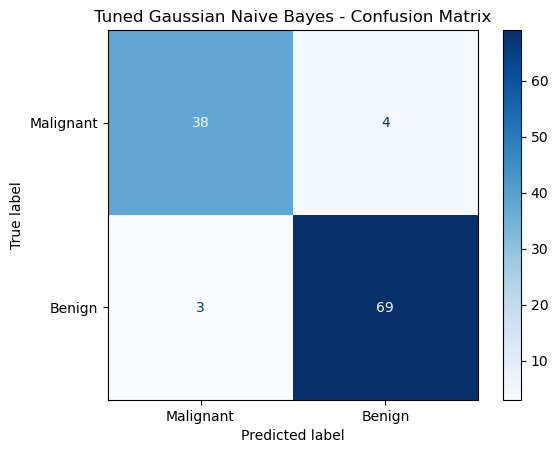

In [24]:
# tuned confusion matrix

cm_tuned = confusion_matrix(y_test, y_tuned_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned,display_labels=['Malignant', 'Benign'])

disp.plot(cmap='Blues')
plt.title('Tuned Gaussian Naive Bayes - Confusion Matrix')
plt.show()

In [25]:

comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Original GaussianNB': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ],
    'Tuned GaussianNB': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

display(comparison)


,Metric,Original GaussianNB,Tuned GaussianNB
0,Accuracy,0.938596,0.938596
1,Precision,0.945205,0.945205
2,Recall,0.958333,0.958333
3,F1 Score,0.951724,0.951724
4,ROC-AUC,0.987765,0.987765


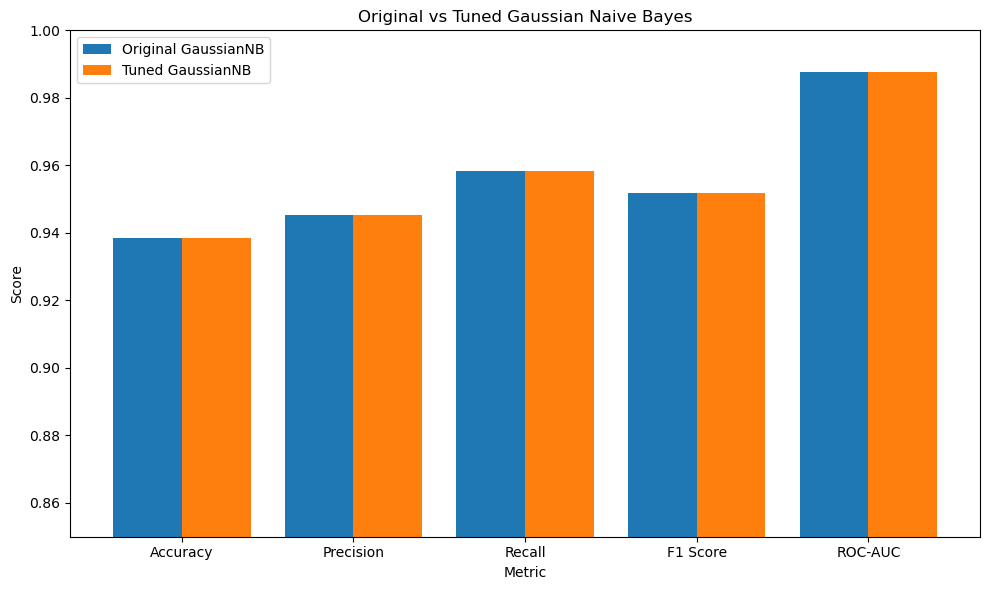

In [26]:

comparison.set_index('Metric').plot(kind='bar',figsize=(10, 6),width=0.8)

plt.title('Original vs Tuned Gaussian Naive Bayes')
plt.ylabel('Score')
plt.ylim(0.85, 1.0)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [27]:

print("Original Malignant Precision:",
      precision_score(y_test, y_test_pred, pos_label=0))

print("Original Malignant Recall:",
      recall_score(y_test, y_test_pred, pos_label=0))

print("\nTuned Malignant Precision:",
      precision_score(y_test, y_tuned_pred, pos_label=0))

print("Tuned Malignant Recall:",
      recall_score(y_test, y_tuned_pred, pos_label=0))


Original Malignant Precision: 0.926829268292683
Original Malignant Recall: 0.9047619047619048

Tuned Malignant Precision: 0.926829268292683
Tuned Malignant Recall: 0.9047619047619048


## Conclusion

Gaussian Naive Bayes was implemented and evaluated using the Breast Cancer Wisconsin dataset.

The baseline classifier achieved an accuracy of 93.86%, an F1 score of 95.17%, and a ROC-AUC of 98.78%.

Hyperparameter tuning was performed using GridSearchCV, with `var_smoothing` as the parameter.

The optimal value was 1e-09, which matched the default configuration. Consequently, tuning did not produce any improvement in test performance.

The final model achieved:
- Accuracy: 93.86%
- Precision: 94.52%
- Recall: 95.83%
- F1 Score: 95.17%
- ROC-AUC: 98.78%

The tuned Gaussian Naive Bayes model was selected as the final model.

**Note:** This experiment is for educational purposes and does not establish clinical suitability. The model should not be used independently for medical diagnosis.


### Multinomial Naive Bayes

### Multinomial Naive Bayes

Multinomial Naive Bayes is a probabilistic classification algorithm commonly used for discrete data, particularly feature counts and frequencies.

It calculates class probabilities using the frequency of feature occurrences within each class.

Unlike Gaussian Naive Bayes, which assumes a normal distribution, Multinomial Naive Bayes is based on a multinomial distribution.

#### Key Characteristics
- Suitable for count-based and frequency-based features.
- Commonly used in text classification and spam detection.
- Requires non-negative feature values.
- Supports Laplace smoothing to handle zero-frequency features.

For this experiment, the continuous breast cancer features will be transformed into non-negative values before training.

In [28]:

from sklearn.preprocessing import MinMaxScaler

# Initialize scaler
minmax_scaler = MinMaxScaler()

# Transform training and testing features
X_train_multi = minmax_scaler.fit_transform(X_train)
X_test_multi = minmax_scaler.transform(X_test)

print("Training Shape:", X_train_multi.shape)
print("Testing Shape:", X_test_multi.shape)

print("Minimum Training Value:", X_train_multi.min())

Training Shape: (455, 30)
Testing Shape: (114, 30)
Minimum Training Value: 0.0


In [29]:
# Initialize model
mnb = MultinomialNB()

# Train model
mnb.fit(X_train_multi, y_train)

# Predictions
y_mnb_pred = mnb.predict(X_test_multi)
y_mnb_proba = mnb.predict_proba(X_test_multi)[:, 1]

In [30]:
# Evaluate
mnb_accuracy = accuracy_score(y_test, y_mnb_pred)
mnb_precision = precision_score(y_test, y_mnb_pred)
mnb_recall = recall_score(y_test, y_mnb_pred)
mnb_f1 = f1_score(y_test, y_mnb_pred)
mnb_roc_auc = roc_auc_score(y_test, y_mnb_proba)

print(f"Accuracy:  {mnb_accuracy:.6f}")
print(f"Precision: {mnb_precision:.6f}")
print(f"Recall:    {mnb_recall:.6f}")
print(f"F1 Score:  {mnb_f1:.6f}")
print(f"ROC-AUC:   {mnb_roc_auc:.6f}")

Accuracy:  0.859649
Precision: 0.818182
Recall:    1.000000
F1 Score:  0.900000
ROC-AUC:   0.938161


In [31]:
# classification report

print(classification_report(y_test,y_mnb_pred,target_names=['Malignant', 'Benign']))


              precision    recall  f1-score   support

   Malignant       1.00      0.62      0.76        42
      Benign       0.82      1.00      0.90        72

    accuracy                           0.86       114
   macro avg       0.91      0.81      0.83       114
weighted avg       0.89      0.86      0.85       114



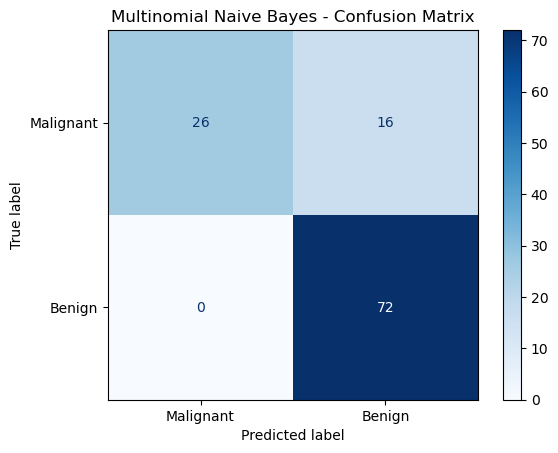

In [32]:
# confusion matrix
cm_mnb = confusion_matrix(y_test, y_mnb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mnb,
    display_labels=['Malignant', 'Benign']
)

disp.plot(cmap='Blues')
plt.title('Multinomial Naive Bayes - Confusion Matrix')
plt.show()

### Bernoulli Naive Bayes


### Bernoulli Naive Bayes

Bernoulli Naive Bayes is a probabilistic classification algorithm designed for binary-valued features.

Unlike Gaussian Naive Bayes, which works with continuous numerical features, Bernoulli Naive Bayes models whether a feature is present or absent.

Each feature is represented as:
- 0: Feature absent
- 1: Feature present

The algorithm calculates class probabilities based on the occurrence and absence of features.

#### Key Characteristics
- Designed for binary features.
- Uses a Bernoulli distribution.
- Commonly applied in document classification and spam detection.
- Supports Laplace smoothing.
- Considers both feature presence and absence.


In [33]:

from sklearn.preprocessing import Binarizer

# Initialize binarizer
binarizer = Binarizer(threshold=0)

# Transform features
X_train_bern = binarizer.fit_transform(X_train)
X_test_bern = binarizer.transform(X_test)

print("Training Shape:", X_train_bern.shape)
print("Testing Shape:", X_test_bern.shape)

print("Unique Training Values:", np.unique(X_train_bern))

Training Shape: (455, 30)
Testing Shape: (114, 30)
Unique Training Values: [0. 1.]


In [34]:

# Use training feature medians as thresholds
feature_medians = X_train.median()

# Convert values above the median to 1, otherwise 0
X_train_bern = (X_train > feature_medians).astype(int)
X_test_bern = (X_test > feature_medians).astype(int)

print("Training Shape:", X_train_bern.shape)
print("Testing Shape:", X_test_bern.shape)

print("\nUnique Training Values:")
print(np.unique(X_train_bern))


Training Shape: (455, 30)
Testing Shape: (114, 30)

Unique Training Values:
[0 1]


In [36]:
# Initialize model
bnb = BernoulliNB()

# Train model
bnb.fit(X_train_bern, y_train)

# Predictions
y_bnb_pred = bnb.predict(X_test_bern)
y_bnb_proba = bnb.predict_proba(X_test_bern)[:, 1]

In [38]:
# evaluation
bnb_accuracy = accuracy_score(y_test, y_bnb_pred)
bnb_precision = precision_score(y_test, y_bnb_pred)
bnb_recall = recall_score(y_test, y_bnb_pred)
bnb_f1 = f1_score(y_test, y_bnb_pred)
bnb_roc_auc = roc_auc_score(y_test, y_bnb_proba)

print(f"Accuracy:  {bnb_accuracy:.6f}")
print(f"Precision: {bnb_precision:.6f}")
print(f"Recall:    {bnb_recall:.6f}")
print(f"F1 Score:  {bnb_f1:.6f}")
print(f"ROC-AUC:   {bnb_roc_auc:.6f}")

Accuracy:  0.912281
Precision: 0.969697
Recall:    0.888889
F1 Score:  0.927536
ROC-AUC:   0.971230


In [39]:
# classification report

print(classification_report(y_test,y_bnb_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.83      0.95      0.89        42
      Benign       0.97      0.89      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



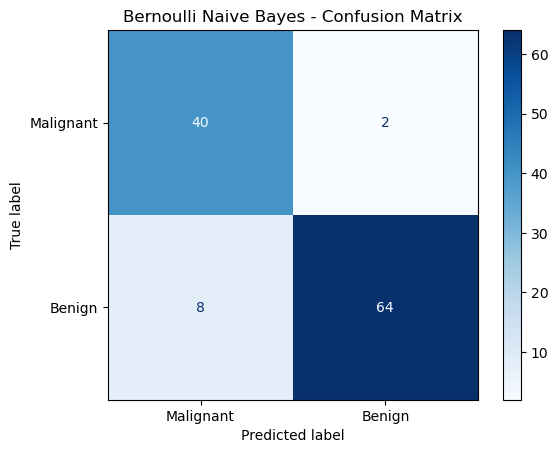

In [40]:
# confusion matrix
cm_bnb = confusion_matrix(y_test, y_bnb_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_bnb,display_labels=['Malignant', 'Benign'])

disp.plot(cmap='Blues')
plt.title('Bernoulli Naive Bayes - Confusion Matrix')
plt.show()

In [41]:

nb_comparison = pd.DataFrame({
    'Model': [
        'GaussianNB',
        'MultinomialNB',
        'BernoulliNB'
    ],
    'Accuracy': [
        accuracy,
        mnb_accuracy,
        bnb_accuracy
    ],
    'Precision': [
        precision,
        mnb_precision,
        bnb_precision
    ],
    'Recall': [
        recall,
        mnb_recall,
        bnb_recall
    ],
    'F1 Score': [
        f1,
        mnb_f1,
        bnb_f1
    ],
    'ROC-AUC': [
        roc_auc,
        mnb_roc_auc,
        bnb_roc_auc
    ]
})

display(nb_comparison.round(6))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,GaussianNB,0.938596,0.945205,0.958333,0.951724,0.987765
1,MultinomialNB,0.859649,0.818182,1.000000,0.900000,0.938161
2,BernoulliNB,0.912281,0.969697,0.888889,0.927536,0.971230


In [42]:

malignant_comparison = pd.DataFrame({
    'Model': [
        'GaussianNB',
        'MultinomialNB',
        'BernoulliNB'
    ],
    'Malignant Precision': [
        precision_score(y_test, y_test_pred, pos_label=0),
        precision_score(y_test, y_mnb_pred, pos_label=0),
        precision_score(y_test, y_bnb_pred, pos_label=0)
    ],
    'Malignant Recall': [
        recall_score(y_test, y_test_pred, pos_label=0),
        recall_score(y_test, y_mnb_pred, pos_label=0),
        recall_score(y_test, y_bnb_pred, pos_label=0)
    ]
})

display(malignant_comparison.round(6))

,Model,Malignant Precision,Malignant Recall
0,GaussianNB,0.926829,0.904762
1,MultinomialNB,1.000000,0.619048
2,BernoulliNB,0.833333,0.952381


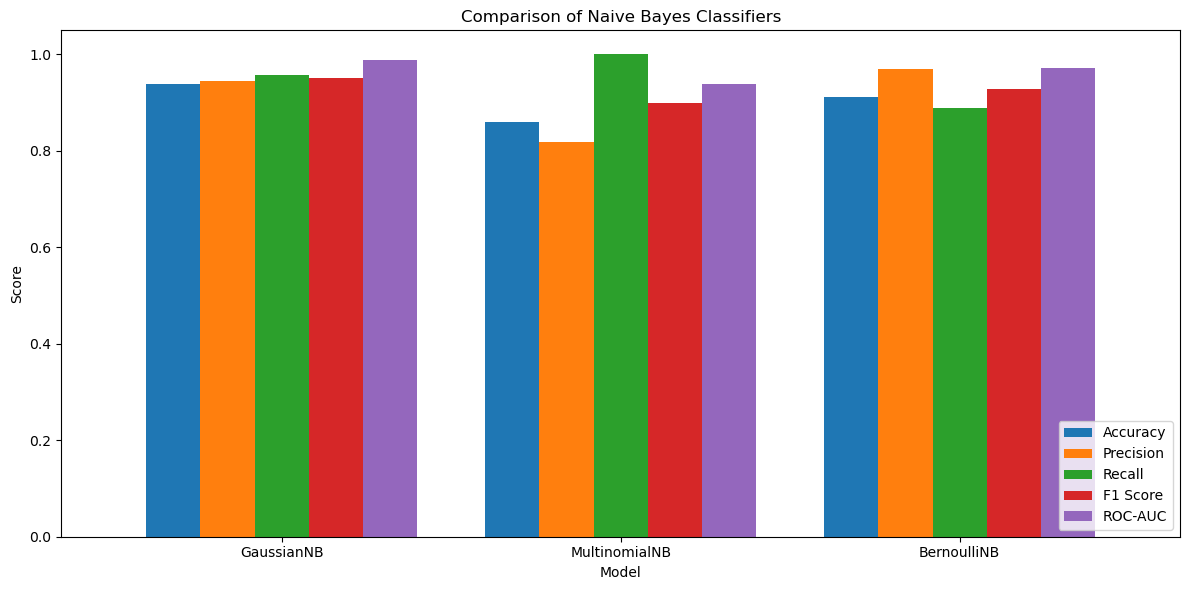

In [43]:

nb_comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Comparison of Naive Bayes Classifiers')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Comparison of Naive Bayes Variants

Three Naive Bayes variants were evaluated: Gaussian Naive Bayes, Multinomial Naive Bayes, and Bernoulli Naive Bayes.

### Key Findings

- **GaussianNB** achieved the highest accuracy (93.86%), F1 score (95.17% for the benign class), and ROC-AUC (98.78%). It provided the strongest overall performance.
- **MultinomialNB** achieved 100% recall for the benign class but had the lowest malignant recall (61.90%), making it less effective at identifying malignant cases.
- **BernoulliNB** achieved the highest malignant recall (95.24%), although its malignant precision was lower (83.33%).

### Final Model Selection

GaussianNB was selected as the primary model because it achieved the strongest overall performance and is naturally appropriate for continuous numerical features.

BernoulliNB demonstrated a useful alternative by identifying a higher proportion of malignant cases, although this came with more false-positive malignant predictions.

The comparison also demonstrates that model selection should consider the problem's objectives and the consequences of different classification errors, rather than relying on accuracy alone.

**Limitation:** This experiment uses the Breast Cancer Wisconsin dataset for educational purposes. These models are not clinically validated and should not be used for medical diagnosis.